In [47]:
import SimpleITK as sitk 
from pathlib import Path
import numpy as np
import pickle
import sys
sys.path.append('../scripts')
import gpa
import vtk
import numpy as np
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd

In [84]:
process_folder = Path(r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_ablormal")

abnormals_csv = Path(r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/sel_ko.csv")
labels = pd.read_csv(abnormals_csv)
labels['frobenius'] = [np.NAN]*(len(labels.index))
w_t_cohorts =   "/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/wt_cohorts_pts.pkl"

In [6]:
tmp = open(w_t_cohorts,'rb')
wt_coh = pickle.load(tmp)
tmp.close()
len(wt_coh)

2

In [19]:
ref_mesh_f, _,shapes_f = gpa.gpa(wt_coh['F'], max_iterations=100, threshold=1e-14)
ref_mesh_m,_, shapes_m = gpa.gpa(wt_coh['M'], max_iterations=100, threshold=1e-14)
refs = {"M": ref_mesh_m,'F': ref_mesh_f}

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/349 [00:00<?, ?it/s]

Procrustes distance  833.3290669704833


  0%|          | 0/349 [00:00<?, ?it/s]

Procrustes distance  0.006803053509711684


...

  0%|          | 0/416 [00:00<?, ?it/s]

Procrustes distance  8.824552146136045e-14


  0%|          | 0/416 [00:00<?, ?it/s]

Procrustes distance  5.074827116024641e-19


  0%|          | 0/417 [00:00<?, ?it/s]

In [24]:
def compute_center_of_mesh(mesh):
    centerOfMassFilter = vtk.vtkCenterOfMass()
    centerOfMassFilter.SetInputData(mesh)
    centerOfMassFilter.SetUseScalarsAsWeights(False)
    centerOfMassFilter.Update();
    center = centerOfMassFilter.GetCenter()
    return center

def read_mesh_pts(file_name):
    reader = vtk.vtkOBJReader()
    reader.SetFileName(file_name)
    reader.Update()
    mesh = reader.GetOutput()
    points = mesh.GetPoints()
    center_of_mesh = np.array( compute_center_of_mesh(mesh) )
    num_of_points = points.GetNumberOfPoints()
    res_mesh = []
    for i in range(points.GetNumberOfPoints()):
        pt = points.GetPoint(i)
        res_mesh.append(list( np.array( pt) - center_of_mesh ))
    return np.array(res_mesh)




In [85]:
result = {}


for fold in tqdm(process_folder.iterdir()):
    if not (fold / "head_affine_registered.obj").exists():
        continue
    gender = fold.name.split('_')[1]
    gene = fold.name.split('_')[0]
    
    if not gene in result.keys():
        result[gene] = {}
    mesh_pts = read_mesh_pts(str(fold / "head_affine_registered.obj"))
    proc_dist = gpa.procreustes_alignment(refs[gender],mesh_pts)[1]
    result[gene][fold.name] = proc_dist
    tmp = labels['frobenius'].mask(labels['SPECIMEN_ID']== fold.name.split("_")[-1],proc_dist)
    labels['frobenius'] = tmp
 

0it [00:00, ?it/s]

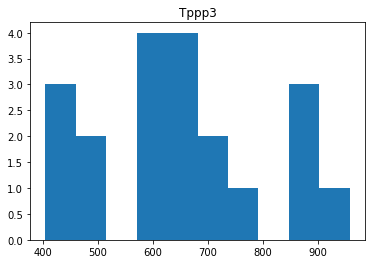

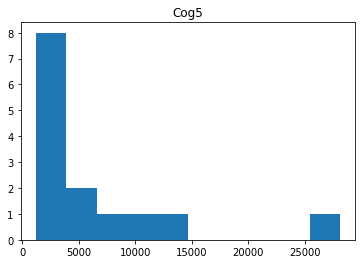

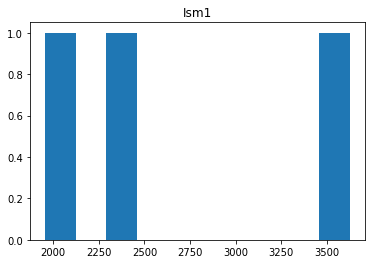

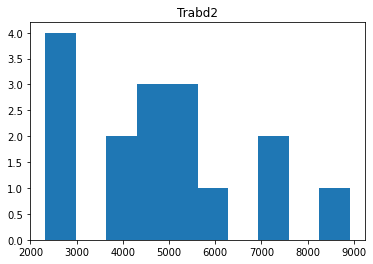

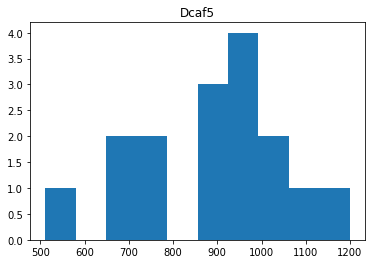

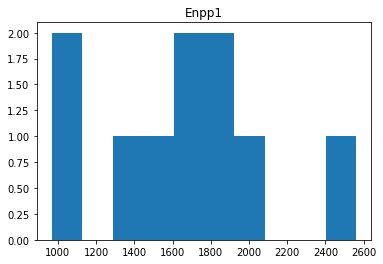

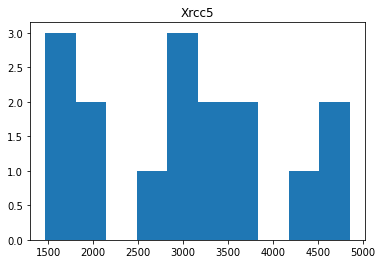

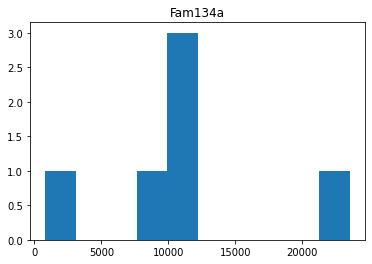

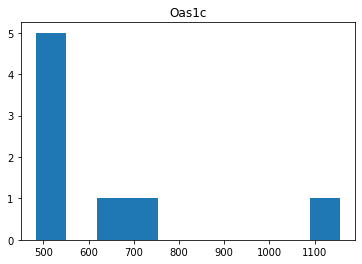

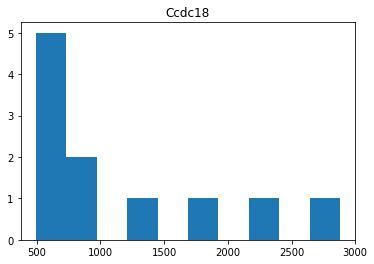

In [44]:
for gene in result.keys():
    
    
    
    fig = plt.figure()
    plt.title(gene)
    plt.hist(result[gene].values())
    
    #pd.DataFrame(result[gene].values(),index=result[gene].keys()).hist(title=gene)
    


<AxesSubplot:title={'center':'frobenius'}, xlabel='[VALUE_CATEGORY]'>

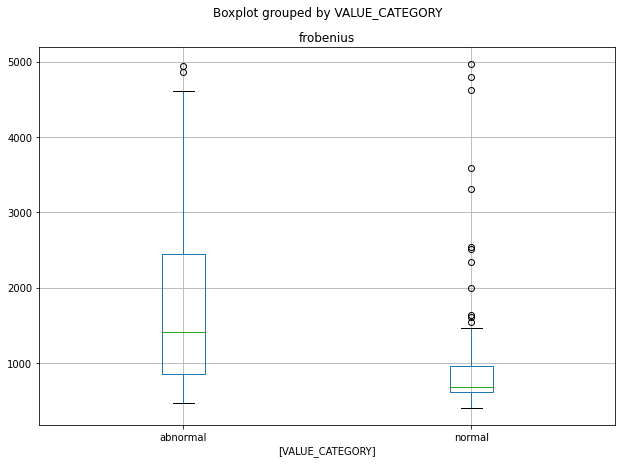

In [86]:
labels[['frobenius','VALUE_CATEGORY']].loc[labels['frobenius']<5000].boxplot(by='VALUE_CATEGORY',figsize=(10,7))

In [112]:
model_for = labels[['frobenius','VALUE_CATEGORY']].loc[labels['frobenius']<5000]
model_for = model_for.dropna()
x = range(500,2000,10)
true_p = []
all_p = []
all_neg = []
true_neg = []
for frob in x: 
    
    tmp_ab = model_for.loc[model_for['frobenius'] >= frob ]
    t_all_pos = len(tmp_ab) #all detected positives(as abnormals) 
    t_true_pos = len(tmp_ab.loc[tmp_ab['VALUE_CATEGORY']=='abnormal']) # correctly identified
    tmp_ab = model_for.loc[model_for['frobenius'] < frob ]
    t_true_neg = len(tmp_ab.loc[tmp_ab['VALUE_CATEGORY']=='normal'])
    t_all_neg = len(tmp_ab)
    true_p.append(t_true_pos)
    all_p.append(t_all_pos)
    all_neg.append(t_all_neg)
    true_neg.append(t_true_neg)
#    break
model_for = pd.DataFrame()
model_for['tp'] = true_p
model_for['ap'] = all_p
model_for['an'] = all_neg
model_for['tn'] = true_neg
model_for['sensitivity'] = model_for['tp'] / model_for['ap']
model_for['specificity'] = model_for['tn'] / model_for['an']
model_for['accuracy'] = (model_for['tp'] +model_for['tn']) / (model_for['an'] + model_for['ap'])
model_for.index = x

<AxesSubplot:>

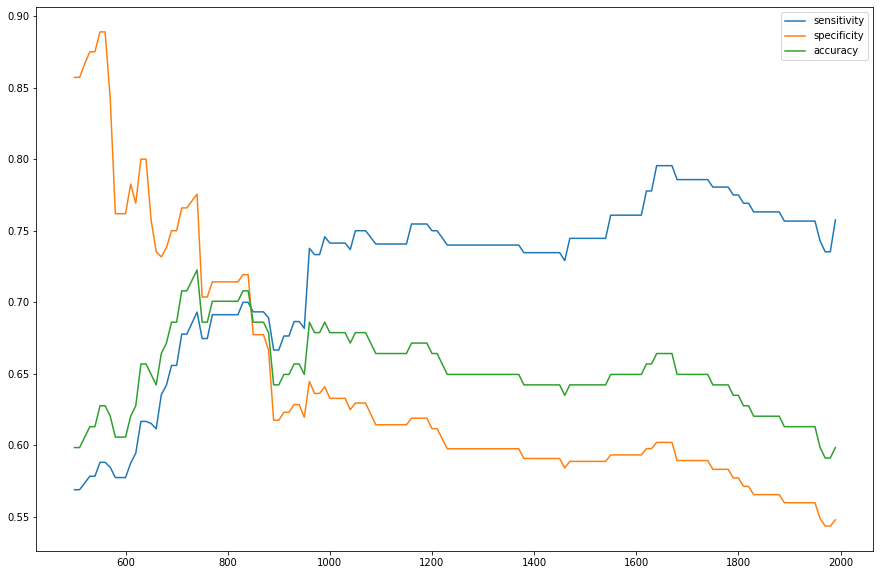

In [114]:
model_for[['sensitivity','specificity','accuracy']].plot(figsize=(15,10))

In [95]:
x = pd.DataFrame()
x['a'] = list(range(100))
x

,a
0,0
1,1
2,2
3,3
4,4
...,...
95,95
96,96
97,97
98,98
